# OP-FL v2 — 02. Baselines fédérées et test de H1 (mortalité)

**Question (H1).** Le processus d'observation (M, Δ, C) aide-t-il à prédire la mortalité **à l'intérieur** de la fédération,
et ce bénéfice **se transporte-t-il mal** vers des hôpitaux jamais vus (gain plus faible, variable d'un hôpital à l'autre, calibration dégradée) ?
Si oui, le problème que veut résoudre OP-FL existe : c'est le point **Go / No-Go** du projet.

**Modèles comparés** (même FedAvg, même tête, mêmes plis, mêmes seeds) :

| Nom | Entrée temporelle | Niveau de l'échelle d'ablation |
|---|---|---|
| `x_only` | X seul | 0 |
| `obs_only` | [M, Δ, C] seuls | mesure du signal d'observation |
| `x_obs` | [X, M, Δ, C] concaténés | 1 |
| `grud` | GRU-D (décroissance apprise selon M et Δ) | 1, référence de la littérature |

Toutes les variantes : GRU (64) → dernier état caché ‖ S → MLP (32) → logit.

| Étape | Contenu |
|---|---|
| 0 | Configuration, vérification du protocole |
| 1 | Module `src/opfl_metrics.py` (discrimination, calibration, méta-analyse) |
| 2 | Module `src/opfl_models.py` (GRU, GRU-D) |
| 3 | Module `src/opfl_fed.py` (chargement d'un pli, FedAvg) |
| 4 | Tests unitaires des modules |
| 5 | Essai rapide sur le pli 0 + estimation du temps de calcul |
| 6 | **Boucle principale** : modèles × plis × seeds (reprend là où elle s'est arrêtée) |
| 7 | Métriques par exécution et par hôpital |
| 8 | Tableau de synthèse + différences appariées par pli |
| 9 | Hétérogénéité du gain entre hôpitaux tenus à l'écart (méta-analyse) |
| 10 | Décision H1 (critères fixés à l'avance) |
| 11 | Contrôles |

**Règles respectées** : sélection du meilleur round sur le split `val` **poolé des hôpitaux d'entraînement** uniquement ;
hôpitaux tenus à l'écart évalués sur `val + test` ; le test verrouillé n'est **jamais** chargé ici.

## Étape 0 — Configuration

* `SEEDS` : 5 seeds pour les résultats définitifs. Pour un premier passage plus court, mettez 3 seeds : la boucle de l'étape 6 complétera plus tard les seeds manquantes sans refaire les autres.
* `EXPECTED_PROTOCOL_HASH` : la cellule s'arrête si le protocole a changé.

In [2]:
# ============================================================
# ÉTAPE 0 — CONFIGURATION
# ============================================================
import sys, os, json, time, importlib
from pathlib import Path
import numpy as np
import pandas as pd
import torch

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

PROJECT_DIR = Path("..")
DATA_DIR = PROJECT_DIR / "data_v1"
SRC_DIR = PROJECT_DIR / "src"
RES_DIR = PROJECT_DIR / "results" / "02_baselines"
PRED_DIR, HIST_DIR, FIG_DIR = RES_DIR / "preds", RES_DIR / "history", RES_DIR / "figures"
for d in [PRED_DIR, HIST_DIR, FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(SRC_DIR.resolve()))

EXPECTED_PROTOCOL_HASH = "d92099ea7c11d517"
protocol = json.loads((DATA_DIR / "splits" / "protocol.json").read_text(encoding="utf-8"))
assert protocol["hash"] == EXPECTED_PROTOCOL_HASH, (
    f"Protocole inattendu ({protocol['hash']}) : les données ont été régénérées. Ne pas continuer.")

TASK = "mortality"
MODELS = ["x_only", "obs_only", "x_obs", "grud"]
FOLDS = [0, 1, 2, 3, 4]
# SEEDS = [11, 22, 33, 44, 55]
SEEDS = [11, 22, 33]
CFG = {
    "rounds": 30,           # rounds FedAvg
    "client_frac": 0.5,     # fraction des hôpitaux d'entraînement tirés à chaque round
    "local_epochs": 1,
    "lr": 1e-3,             # Adam, réinitialisé à chaque round local
    "batch_size": 64,
    "hidden": 64,           # GRU
    "head": 32,             # MLP de la tête
    "dropout": 0.1,
    "grad_clip": 1.0,
}
MIN_EVENTS_HOSP = 5         # AUROC par hôpital seulement si >= 5 décès et >= 5 survivants
N_BOOT = 200                # bootstrap intra-hôpital (étape 9)

N_THREADS = max(1, (os.cpu_count() or 2) - 1)
torch.set_num_threads(N_THREADS)
save_cfg = {"task": TASK, "models": MODELS, "folds": FOLDS, "seeds": SEEDS, "cfg": CFG,
            "protocol_hash": protocol["hash"], "min_events_hosp": MIN_EVENTS_HOSP}
(RES_DIR / "config.json").write_text(json.dumps(save_cfg, indent=2), encoding="utf-8")

print(f"PyTorch {torch.__version__} | {N_THREADS} threads CPU | protocole {protocol['hash']}")
print(f"{len(MODELS)} modèles × {len(FOLDS)} plis × {len(SEEDS)} seeds = {len(MODELS) * len(FOLDS) * len(SEEDS)} exécutions")

PyTorch 2.9.1+cpu | 3 threads CPU | protocole d92099ea7c11d517
4 modèles × 5 plis × 3 seeds = 60 exécutions


## Étape 1 — Module de métriques `src/opfl_metrics.py`

* Discrimination : AUROC, AUPRC.
* Calibration : Brier, ECE à classes d'effectif égal (*equal-mass*), **pente de calibration** (idéal 1) et **calibration-in-the-large** (idéal 0 ; > 0 = sous-estimation du risque).
* Méta-analyse à effets aléatoires (DerSimonian-Laird) : servira à l'étape 9 et, plus tard, au test verrouillé.

## Étape 2 — Module des modèles `src/opfl_models.py`

* `GRUClassifier` : un GRU sur l'entrée choisie (`x_only`, `obs_only` ou `x_obs`).
* `GRUD` (Che et al., 2018) : à chaque pas, une valeur absente est remplacée par la dernière valeur observée, ramenée vers la moyenne (0 après z-score) avec une décroissance apprise selon Δ ; l'état caché décroît aussi selon Δ ; le masque M entre dans la cellule.

## Étape 3 — Module fédéré `src/opfl_fed.py`

* `load_fold` : charge un pli (normalisation `global` du pli). Hôpitaux d'entraînement : `train`, `val`, `test` ; hôpitaux tenus à l'écart : `val + test` seulement. Refuse de charger le test verrouillé.
* `run_federated` : FedAvg pondéré par la taille du split `train` ; à chaque round, la moitié des hôpitaux d'entraînement entraîne une époque locale (Adam réinitialisé) ; après agrégation, AUROC sur le `val` poolé des hôpitaux d'entraînement ; on garde le **meilleur round**. Le modèle retenu prédit ensuite :
  * `val` et `test` des hôpitaux d'entraînement (rôles `val` et `intra`) ;
  * `val + test` des hôpitaux tenus à l'écart (rôle `transfer`).

## Étape 4 — Tests unitaires

Vérifie les métriques sur des cas connus, la forme des sorties des 4 modèles, et que FedAvg de modèles identiques redonne le même modèle.

In [3]:
# ============================================================
# ÉTAPE 4 — IMPORT ET TESTS UNITAIRES DES MODULES
# ============================================================
import opfl_data, opfl_metrics, opfl_models, opfl_fed
for m in (opfl_data, opfl_metrics, opfl_models, opfl_fed):
    importlib.reload(m)
from opfl_metrics import summarize, auroc, random_effects, mean_ci_t, paired_auroc_diff_boot, both_classes
from opfl_models import build_model, n_params
from opfl_fed import load_fold, run_federated, fedavg_

rng = np.random.default_rng(0)
# 1) métriques : prédicteur parfait, aléatoire, et calibration d'un modèle bien calibré
y = rng.integers(0, 2, 4000)
assert abs(auroc(y, y + 0.0) - 1) < 1e-9
assert abs(auroc(y, rng.random(4000)) - 0.5) < 0.05
p_true = rng.uniform(0.02, 0.6, 20000); y_cal = (rng.random(20000) < p_true).astype(int)
s = summarize(y_cal, p_true)
assert abs(s["cal_slope"] - 1) < 0.1 and abs(s["cal_citl"]) < 0.05 and s["ece"] < 0.02, s
s_shift = summarize(y_cal, p_true * 0.5)            # risque sous-estimé -> CITL > 0
assert s_shift["cal_citl"] > 0.3, s_shift
# 2) méta-analyse : effets homogènes -> tau² ≈ 0 ; hétérogènes -> tau² > 0
assert random_effects(np.zeros(30) + 0.01, np.full(30, 1e-4))["tau2"] < 1e-9
assert random_effects(rng.normal(0, 0.05, 30), np.full(30, 1e-4))["Q_pvalue"] < 0.01
# 3) modèles : formes et nombres de paramètres
F_, S_ = 29, 21
batch = [torch.randn(8, 24, F_), torch.randint(0, 2, (8, 24, F_)).float(), torch.rand(8, 24, F_),
         torch.rand(8, 24, F_), torch.randn(8, S_)]
for name in MODELS:
    mdl = build_model(name, F_, S_, CFG["hidden"], CFG["head"], CFG["dropout"])
    out = mdl(*batch)
    assert out.shape == (8,) and torch.isfinite(out).all()
    print(f"  {name:9s} : {n_params(mdl):6d} paramètres")
# 4) FedAvg de copies identiques = modèle inchangé
mdl = build_model("x_obs", F_, S_)
ref = {k: v.clone() for k, v in mdl.state_dict().items()}
fedavg_(mdl, [ref, ref, ref], [10, 20, 30])
assert all(torch.allclose(ref[k], mdl.state_dict()[k]) for k in ref)
print("Tests unitaires : OK")

  x_only    :  21025 paramètres
  obs_only  :  32161 paramètres
  x_obs     :  37729 paramètres
  grud      :  28571 paramètres
Tests unitaires : OK


## Étape 5 — Essai rapide et estimation du temps de calcul

Charge le pli 0, entraîne chaque modèle pendant 2 rounds (rien n'est sauvegardé), puis estime la durée de la boucle complète.
Si l'estimation est trop longue, réduisez `SEEDS` à 3 dans l'étape 0 pour un premier passage.

In [4]:
# ============================================================
# ÉTAPE 5 — ESSAI RAPIDE SUR LE PLI 0 + ESTIMATION DU TEMPS
# ============================================================
t0 = time.time()
fd = load_fold(DATA_DIR, FOLDS[0], task=TASK)
t_load = time.time() - t0
n_tr = sum(len(fd["clients"][h]["train"]["y"]) for h in fd["train_h"])
n_ho = sum(len(fd["clients"][h]["valtest"]["y"]) for h in fd["held_h"])
print(f"Pli {fd['fold']} chargé en {t_load:.0f} s : {len(fd['train_h'])} hôpitaux d'entraînement "
      f"({n_tr} séjours train), {len(fd['held_h'])} tenus à l'écart ({n_ho} séjours val+test)")
print(f"Entrées : {fd['n_feat']} variables temporelles, {fd['n_static']} variables statiques")

sec_per_round = {}
for name in MODELS:
    _, hist, info = run_federated(fd, name, SEEDS[0], CFG, rounds=2, verbose=False)
    sec_per_round[name] = float(hist["seconds"].mean())
    print(f"  {name:9s} : {sec_per_round[name]:.1f} s par round | AUROC val après 2 rounds {hist['val_auroc'].iloc[-1]:.3f}")
del fd

total = (sum(sec_per_round.values()) * CFG["rounds"] * len(SEEDS) + t_load) * len(FOLDS)
print(f"\nDurée estimée de l'étape 6 : {total / 3600:.1f} h "
      f"({len(MODELS)} modèles × {len(FOLDS)} plis × {len(SEEDS)} seeds × {CFG['rounds']} rounds)")

Pli 0 chargé en 8 s : 48 hôpitaux d'entraînement (37372 séjours train), 12 tenus à l'écart (3813 séjours val+test)
Entrées : 29 variables temporelles, 21 variables statiques
  x_only    : 12.9 s par round | AUROC val après 2 rounds 0.787
  obs_only  : 9.1 s par round | AUROC val après 2 rounds 0.661
  x_obs     : 9.1 s par round | AUROC val après 2 rounds 0.768
  grud      : 18.4 s par round | AUROC val après 2 rounds 0.757

Durée estimée de l'étape 6 : 6.2 h (4 modèles × 5 plis × 3 seeds × 30 rounds)


## Étape 6 — Boucle principale (reprise automatique)

Pour chaque pli, chaque modèle et chaque seed : entraînement FedAvg, choix du meilleur round sur `val`, prédictions sauvegardées dans `results/02_baselines/preds/`.
**Une exécution déjà terminée n'est jamais refaite** : si la cellule est interrompue, relancez-la et elle reprendra là où elle s'est arrêtée.

In [5]:
# ============================================================
# ÉTAPE 6 — BOUCLE PRINCIPALE : MODÈLES × PLIS × SEEDS
# ============================================================
def pred_path(model, fold, seed):
    return PRED_DIR / f"{model}__fold{fold}__seed{seed}.parquet"

runs_csv = RES_DIR / "runs.csv"
n_total = len(MODELS) * len(FOLDS) * len(SEEDS)
t_start, n_done_now = time.time(), 0
for fold in FOLDS:
    todo = [(m, s) for m in MODELS for s in SEEDS if not pred_path(m, fold, s).exists()]
    if not todo:
        print(f"Pli {fold} : déjà complet.")
        continue
    fd = load_fold(DATA_DIR, fold, task=TASK)
    for m, s in todo:
        n_existing = sum(pred_path(mm, ff, ss).exists() for mm in MODELS for ff in FOLDS for ss in SEEDS)
        print(f"[{n_existing + 1}/{n_total}] pli {fold} | {m} | seed {s}")
        preds, hist, info = run_federated(fd, m, s, CFG)
        hist.assign(model=m, fold=fold, seed=s).to_csv(HIST_DIR / f"{m}__fold{fold}__seed{s}.csv", index=False)
        row = pd.DataFrame([{"model": m, "fold": fold, "seed": s, **info,
                             "finished_at": pd.Timestamp.now().isoformat(timespec="seconds")}])
        row.to_csv(runs_csv, mode="a", header=not runs_csv.exists(), index=False)
        preds.assign(model=m, fold=fold, seed=s).to_parquet(pred_path(m, fold, s), index=False)  # en dernier
        n_done_now += 1
        el = time.time() - t_start
        left = n_total - sum(pred_path(mm, ff, ss).exists() for mm in MODELS for ff in FOLDS for ss in SEEDS)
        print(f"    meilleur round {info['best_round']} | AUROC val {info['best_val_auroc']:.4f} | "
              f"{info['seconds'] / 60:.1f} min | reste ≈ {el / n_done_now * left / 3600:.1f} h")
    del fd

n_files = sum(pred_path(m, f, s).exists() for m in MODELS for f in FOLDS for s in SEEDS)
print(f"\nExécutions terminées : {n_files} / {n_total}")

[1/60] pli 0 | x_only | seed 11
    round 30/30 | perte 0.2253 | AUROC val 0.8444 | 7.4 s    
    meilleur round 29 | AUROC val 0.8444 | 4.2 min | reste ≈ 4.3 h
[2/60] pli 0 | x_only | seed 22
    round 30/30 | perte 0.2334 | AUROC val 0.8435 | 8.9 s    
    meilleur round 30 | AUROC val 0.8435 | 5.2 min | reste ≈ 4.5 h
[4/60] pli 0 | obs_only | seed 11
    round 30/30 | perte 0.2638 | AUROC val 0.7752 | 8.2 s    
    meilleur round 29 | AUROC val 0.7764 | 4.0 min | reste ≈ 4.3 h
[5/60] pli 0 | obs_only | seed 22
    round 30/30 | perte 0.2704 | AUROC val 0.7699 | 8.2 s    
    meilleur round 30 | AUROC val 0.7699 | 4.4 min | reste ≈ 4.2 h
[6/60] pli 0 | obs_only | seed 33
    round 30/30 | perte 0.2776 | AUROC val 0.7730 | 8.6 s   
    meilleur round 29 | AUROC val 0.7733 | 4.2 min | reste ≈ 4.0 h
[7/60] pli 0 | x_obs | seed 11
    round 30/30 | perte 0.2238 | AUROC val 0.8492 | 8.3 s    
    meilleur round 29 | AUROC val 0.8493 | 4.4 min | reste ≈ 4.0 h
[8/60] pli 0 | x_obs | seed 22

## Étape 7 — Métriques par exécution et par hôpital

Pour chaque exécution et chaque rôle :
* `intra` : split `test` des hôpitaux d'entraînement (patients jamais vus, hôpitaux connus) ;
* `transfer` : `val + test` des hôpitaux tenus à l'écart (hôpitaux jamais vus).

Métriques poolées, puis par hôpital (si ≥ 5 décès et ≥ 5 survivants) : moyenne (macro) et pire hôpital.

In [6]:
# ============================================================
# ÉTAPE 7 — MÉTRIQUES PAR EXÉCUTION ET PAR HÔPITAL
# ============================================================
files = sorted(PRED_DIR.glob("*.parquet"))
preds = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)
print(f"{len(files)} exécutions, {len(preds)} prédictions")

run_rows, hosp_rows = [], []
for (m, f, s), g in preds.groupby(["model", "fold", "seed"], sort=True):
    for role in ("intra", "transfer"):
        r = g[g["role"] == role]
        per_h = []
        for h, gh in r.groupby("hospitalid"):
            met = summarize(gh["y"].to_numpy(), gh["p"].to_numpy())
            met["evaluable"] = both_classes(gh["y"].to_numpy(), MIN_EVENTS_HOSP)
            if not met["evaluable"]:
                met["auroc"] = np.nan
            hosp_rows.append({"model": m, "fold": f, "seed": s, "role": role, "hospitalid": h, **met})
            per_h.append(met)
        aucs = np.array([x["auroc"] for x in per_h], float)
        run_rows.append({"model": m, "fold": f, "seed": s, "role": role,
                         **summarize(r["y"].to_numpy(), r["p"].to_numpy()),
                         "macro_auroc": float(np.nanmean(aucs)), "worst_auroc": float(np.nanmin(aucs)),
                         "n_hosp": len(per_h), "n_hosp_eval": int(np.isfinite(aucs).sum())})

metrics_runs = pd.DataFrame(run_rows)
metrics_hosp = pd.DataFrame(hosp_rows)
metrics_runs.to_csv(RES_DIR / "metrics_runs.csv", index=False)
metrics_hosp.to_csv(RES_DIR / "metrics_hospital.csv", index=False)
print("Écrit : metrics_runs.csv, metrics_hospital.csv")
display(metrics_runs.groupby(["role", "model"])[["n", "events", "n_hosp", "n_hosp_eval"]].mean().round(0))

60 exécutions, 1189560 prédictions
Écrit : metrics_runs.csv, metrics_hospital.csv


n  events  n_hosp  n_hosp_eval
role     model                                         
intra    grud      10574.0   993.0    48.0         48.0
         obs_only  10574.0   993.0    48.0         48.0
         x_obs     10574.0   993.0    48.0         48.0
         x_only    10574.0   993.0    48.0         48.0
transfer grud       3965.0   372.0    12.0         12.0
         obs_only   3965.0   372.0    12.0         12.0
         x_obs      3965.0   372.0    12.0         12.0
         x_only     3965.0   372.0    12.0         12.0

## Étape 8 — Synthèse et différences appariées

1. Tableau moyenne ± écart-type sur toutes les exécutions (plis × seeds).
2. Différences **appariées** avec `x_only` (mêmes patients, même pli, même seed), moyennées sur les seeds dans chaque pli, puis moyenne et IC 95 % de Student sur les 5 plis.
3. **Écart de transport** G = (gain intra) − (gain transfert) : G > 0 signifie que le bénéfice du canal d'observation diminue quand on change d'hôpital.

In [7]:
# ============================================================
# ÉTAPE 8 — TABLEAU DE SYNTHÈSE + DIFFÉRENCES APPARIÉES PAR PLI
# ============================================================
METRICS = ["auroc", "auprc", "brier", "ece", "cal_slope", "cal_citl", "macro_auroc", "worst_auroc"]
mr = pd.read_csv(RES_DIR / "metrics_runs.csv")

agg = mr.groupby(["role", "model"])[METRICS].agg(["mean", "std"])
table = pd.DataFrame({k: agg[(k, "mean")].map("{:.4f}".format) + " ± " + agg[(k, "std")].map("{:.4f}".format)
                      for k in METRICS})
table = table.reindex(pd.MultiIndex.from_product([["intra", "transfer"], MODELS]))
table.to_csv(RES_DIR / "summary_table.csv")
display(table)

# différences appariées vs x_only, moyennées par pli
wide = mr.pivot_table(index=["role", "fold", "seed"], columns="model", values=METRICS)
diff_rows = []
for metric in ["auroc", "auprc", "brier", "cal_citl", "macro_auroc"]:
    for m in [x for x in MODELS if x != "x_only"]:
        d = (wide[(metric, m)] - wide[(metric, "x_only")]).groupby(["role", "fold"]).mean()
        for role in ("intra", "transfer"):
            per_fold = d.loc[role].to_numpy()
            mean, lo, hi = mean_ci_t(per_fold)
            diff_rows.append({"metric": metric, "model": m, "role": role, "diff_vs_x_only": mean,
                              "ci_low": lo, "ci_high": hi, "folds_positive": int((per_fold > 0).sum()),
                              "n_folds": len(per_fold)})
        gi, gt = d.loc["intra"], d.loc["transfer"]
        G = (gi - gt).to_numpy()
        mean, lo, hi = mean_ci_t(G)
        diff_rows.append({"metric": metric, "model": m, "role": "G = intra - transfert", "diff_vs_x_only": mean,
                          "ci_low": lo, "ci_high": hi, "folds_positive": int((G > 0).sum()), "n_folds": len(G)})
diffs = pd.DataFrame(diff_rows)
diffs.to_csv(RES_DIR / "paired_differences.csv", index=False)
display(diffs[diffs["metric"] == "auroc"].round(4))
display(diffs[diffs["metric"].isin(["auprc", "cal_citl", "macro_auroc"])].round(4))

auroc            auprc            brier              ece        cal_slope         cal_citl      macro_auroc      worst_auroc
intra    x_only    0.8510 ± 0.0020  0.4519 ± 0.0052  0.0664 ± 0.0007  0.0105 ± 0.0027  0.9680 ± 0.0371  0.0767 ± 0.0973  0.8454 ± 0.0031  0.5407 ± 0.0904
         obs_only  0.7704 ± 0.0046  0.2994 ± 0.0082  0.0757 ± 0.0009  0.0106 ± 0.0036  1.0071 ± 0.0211  0.0698 ± 0.0946  0.7742 ± 0.0053  0.5464 ± 0.0462
         x_obs     0.8553 ± 0.0017  0.4566 ± 0.0058  0.0661 ± 0.0008  0.0129 ± 0.0039  0.9694 ± 0.0256  0.1244 ± 0.1235  0.8539 ± 0.0023  0.5816 ± 0.0722
         grud      0.8523 ± 0.0022  0.4539 ± 0.0058  0.0664 ± 0.0007  0.0123 ± 0.0032  0.9536 ± 0.0343  0.1068 ± 0.1215  0.8504 ± 0.0022  0.5555 ± 0.0868
transfer x_only    0.8455 ± 0.0082  0.4429 ± 0.0271  0.0671 ± 0.0028  0.0129 ± 0.0038  0.9401 ± 0.0421  0.0626 ± 0.1053  0.8408 ± 0.0105  0.7128 ± 0.0891
         obs_only  0.7693 ± 0.0137  0.2996 ± 0.0224  0.0762 ± 0.0036  0.0203 ± 0.0054  1.0163 ± 0.0518  0.0888 ± 0.2402  0.7740 ± 0.0173  0.6577 ± 0.0458
         x_obs     0.8502 ± 0.0078  0.4517 ± 0.0298  0.0665 ± 0.0025  0.0131 ± 0.0043  0.9546 ± 0.0305  0.1310 ± 0.1492  0.8491 ± 0.0127  0.7222 ± 0.0859
         grud      0.8468 ± 0.0080  0.4456 ± 0.0280  0.0670 ± 0.0026  0.0145 ± 0.0040  0.9289 ± 0.0315  0.1074 ± 0.1580  0.8448 ± 0.0110  0.7129 ± 0.0896

,metric,model,role,diff_vs_x_only,ci_low,ci_high,folds_positive,n_folds
0,auroc,obs_only,intra,-0.0806,-0.0859,-0.0754,0,5
1,auroc,obs_only,transfer,-0.0762,-0.0965,-0.0560,0,5
2,auroc,obs_only,G = intra - transfert,-0.0044,-0.0285,0.0197,2,5
3,auroc,x_obs,intra,0.0042,0.0030,0.0055,5,5
4,auroc,x_obs,transfer,0.0048,0.0032,0.0063,5,5
5,auroc,x_obs,G = intra - transfert,-0.0005,-0.0027,0.0017,2,5
6,auroc,grud,intra,0.0013,0.0002,0.0024,5,5
7,auroc,grud,transfer,0.0013,-0.0032,0.0058,3,5
8,auroc,grud,G = intra - transfert,-0.0000,-0.0055,0.0055,2,5


,metric,model,role,diff_vs_x_only,ci_low,ci_high,folds_positive,n_folds
9,auprc,obs_only,intra,-0.1525,-0.1574,-0.1476,0,5
10,auprc,obs_only,transfer,-0.1432,-0.1604,-0.1261,0,5
11,auprc,obs_only,G = intra - transfert,-0.0093,-0.0281,0.0096,1,5
12,auprc,x_obs,intra,0.0047,0.0021,0.0073,5,5
13,auprc,x_obs,transfer,0.0088,-0.0039,0.0216,4,5
14,auprc,x_obs,G = intra - transfert,-0.0041,-0.0173,0.0090,2,5
15,auprc,grud,intra,0.0020,0.0009,0.0031,5,5
16,auprc,grud,transfer,0.0027,-0.0050,0.0105,4,5
17,auprc,grud,G = intra - transfert,-0.0008,-0.0090,0.0075,3,5
27,cal_citl,obs_only,intra,-0.0069,-0.0920,0.0782,3,5


## Étape 9 — Le gain varie-t-il d'un hôpital à l'autre ?

Chaque hôpital de développement est tenu à l'écart dans exactement un pli : on obtient donc une évaluation de transfert pour les 60 hôpitaux.
Pour chaque hôpital (prédictions moyennées sur les seeds) :
* gain d'AUROC de `x_obs` (et de `grud`) par rapport à `x_only`, avec sa variance par **bootstrap apparié** sur les patients ;
* méta-analyse à effets aléatoires : gain poolé, **τ** (écart-type du vrai gain entre hôpitaux), **I²** et test Q.
  Un Q significatif signifie que le gain varie entre hôpitaux **au-delà du bruit d'échantillonnage**.
* lien avec le profil d'observation de l'hôpital (couverture des gaz du sang, nombre de variables indisponibles).

60 hôpitaux tenus à l'écart évaluables (>= 5 décès et survivants)


,model,k,pooled,ci_low,ci_high,tau2,tau,I2,Q,Q_pvalue,pct_hosp_gain_lt_-0.01,pct_hosp_gain_gt_+0.01,spearman_gain_vs_bloodgas_cov,p_bloodgas,spearman_gain_vs_n_unavailable,p_unavailable
0,obs_only,60,-0.0686,-0.0803,-0.0568,0.0004,0.0209,0.2170,75.3547,0.0742,0.8667,0.0833,-0.0439,0.7391,0.2642,0.0414
1,x_obs,60,0.0044,0.0020,0.0067,0.0000,0.0011,0.0129,59.7713,0.4475,0.0667,0.4167,-0.0112,0.9325,0.1741,0.1835
2,grud,60,0.0018,-0.0001,0.0038,0.0000,0.0000,0.0000,44.9103,0.9123,0.0167,0.2167,0.1172,0.3725,0.1613,0.2182


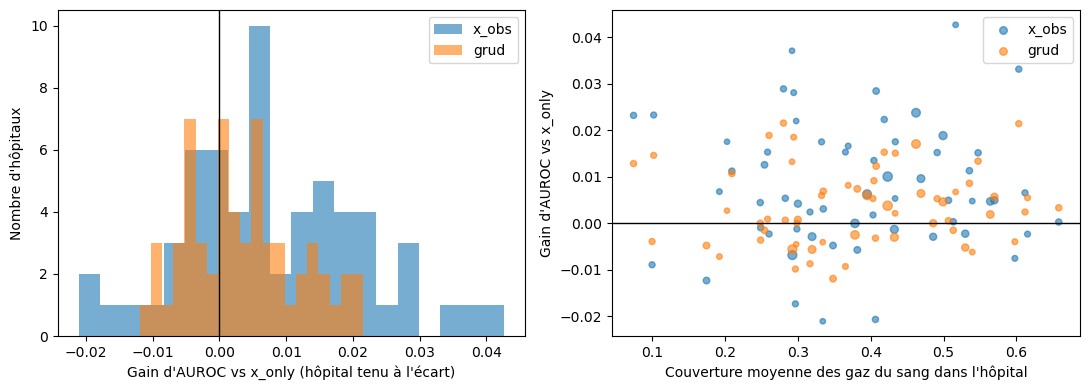

In [8]:
# ============================================================
# ÉTAPE 9 — HÉTÉROGÉNÉITÉ DU GAIN ENTRE HÔPITAUX TENUS À L'ÉCART
# ============================================================
import matplotlib.pyplot as plt
from scipy import stats

tr = preds[preds["role"] == "transfer"]
ens = (tr.groupby(["model", "hospitalid", "stay_id"], sort=False)
         .agg(y=("y", "first"), p=("p", "mean")).reset_index())         # moyenne des seeds
cov = pd.read_csv(DATA_DIR / "reports" / "coverage_by_hospital.csv", index_col=0)
avail = pd.read_csv(DATA_DIR / "reports" / "availability_by_hospital.csv", index_col=0)
BLOODGAS = ["lactate", "pH", "paO2", "paCO2", "FiO2"]
FEATS = [c for c in avail.columns if c != "role"]

rows = []
for h, gh in ens.groupby("hospitalid"):
    base = gh[gh["model"] == "x_only"].set_index("stay_id")
    yv = base["y"].to_numpy()
    if not both_classes(yv, MIN_EVENTS_HOSP):
        continue
    r = {"hospitalid": h, "n": len(yv), "events": int(yv.sum()), "auroc_x_only": auroc(yv, base["p"].to_numpy()),
         "bloodgas_coverage": float(cov.loc[h, BLOODGAS].mean()),
         "n_unavailable": int((avail.loc[h, FEATS] == 0).sum())}
    for m in [x for x in MODELS if x != "x_only"]:
        other = gh[gh["model"] == m].set_index("stay_id").loc[base.index]
        g, v = paired_auroc_diff_boot(yv, base["p"].to_numpy(), other["p"].to_numpy(), n_boot=N_BOOT, seed=int(h))
        r[f"gain_{m}"], r[f"var_{m}"] = g, v
    rows.append(r)
hg = pd.DataFrame(rows)
hg.to_csv(RES_DIR / "hospital_gains_transfer.csv", index=False)
print(f"{len(hg)} hôpitaux tenus à l'écart évaluables (>= {MIN_EVENTS_HOSP} décès et survivants)")

meta_rows = []
for m in [x for x in MODELS if x != "x_only"]:
    ra = random_effects(hg[f"gain_{m}"], hg[f"var_{m}"])
    rho_bg = stats.spearmanr(hg[f"gain_{m}"], hg["bloodgas_coverage"])
    rho_na = stats.spearmanr(hg[f"gain_{m}"], hg["n_unavailable"])
    meta_rows.append({"model": m, **ra,
                      "pct_hosp_gain_lt_-0.01": float((hg[f"gain_{m}"] < -0.01).mean()),
                      "pct_hosp_gain_gt_+0.01": float((hg[f"gain_{m}"] > 0.01).mean()),
                      "spearman_gain_vs_bloodgas_cov": rho_bg.statistic, "p_bloodgas": rho_bg.pvalue,
                      "spearman_gain_vs_n_unavailable": rho_na.statistic, "p_unavailable": rho_na.pvalue})
meta = pd.DataFrame(meta_rows)
meta.to_csv(RES_DIR / "hospital_meta_analysis.csv", index=False)
display(meta.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for m, color in [("x_obs", "tab:blue"), ("grud", "tab:orange")]:
    axes[0].hist(hg[f"gain_{m}"], bins=20, alpha=0.6, label=m, color=color)
    axes[1].scatter(hg["bloodgas_coverage"], hg[f"gain_{m}"], s=12 + hg["events"] / 3, alpha=0.6, label=m, color=color)
axes[0].axvline(0, color="k", lw=1); axes[0].set_xlabel("Gain d'AUROC vs x_only (hôpital tenu à l'écart)")
axes[0].set_ylabel("Nombre d'hôpitaux"); axes[0].legend()
axes[1].axhline(0, color="k", lw=1); axes[1].set_xlabel("Couverture moyenne des gaz du sang dans l'hôpital")
axes[1].set_ylabel("Gain d'AUROC vs x_only"); axes[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "gain_par_hopital.png", dpi=200)
plt.show()

## Étape 10 — Décision H1 (critères fixés **avant** de voir les résultats)

| Critère | Définition | Seuil |
|---|---|---|
| **H1a** — le canal d'observation porte un signal | gain d'AUROC intra de `x_obs` vs `x_only` | IC 95 % sur les plis > 0 |
| **H1b-1** — écart de transport | G = gain intra − gain transfert (AUROC) | moyenne > 0 et ≥ 4 plis sur 5 |
| **H1b-2** — hétérogénéité entre hôpitaux | test Q de la méta-analyse des gains par hôpital | p < 0,05 |
| **H1b-3** — signal d'observation spécifique au site | chute intra → transfert de `obs_only` plus forte que celle de `x_only` | moyenne > 0 et ≥ 4 plis sur 5 |
| **H1b-4** — calibration | \|CITL\| en transfert plus grand pour `x_obs` que pour `x_only` | moyenne > 0 et ≥ 4 plis sur 5 |

* **GO** : H1a et au moins un critère H1b → le problème visé par OP-FL existe ; on passe au niveau 2 (centrage par site).
* **PARTIEL** : H1a seul → le masque aide et se transporte bien sur la mortalité ; on teste quand même le niveau 2, mais l'argument principal se déplacera vers l'AKI et la calibration.
* **NO-GO (mortalité)** : pas de H1a → le canal d'observation n'apporte rien sur la mortalité ; on rediscute avant de continuer (AKI, plan B).

In [9]:
# ============================================================
# ÉTAPE 10 — DÉCISION H1 (CRITÈRES PRÉ-SPÉCIFIÉS)
# ============================================================
d_auc = diffs[diffs["metric"] == "auroc"].set_index(["model", "role"])
def fold_series(metric, model, role):
    w = mr[mr["role"] == role].pivot_table(index=["fold", "seed"], columns="model", values=metric)
    return w[model].groupby("fold").mean()

h1a = d_auc.loc[("x_obs", "intra")]
g = d_auc.loc[("x_obs", "G = intra - transfert")]
q = meta.set_index("model").loc["x_obs"]
drop_obs = fold_series("auroc", "obs_only", "intra") - fold_series("auroc", "obs_only", "transfer")
drop_x = fold_series("auroc", "x_only", "intra") - fold_series("auroc", "x_only", "transfer")
did = (drop_obs - drop_x).to_numpy()
citl = (fold_series("cal_citl", "x_obs", "transfer").abs() - fold_series("cal_citl", "x_only", "transfer").abs()).to_numpy()
n_f = len(FOLDS)
need = max(1, int(np.ceil(0.8 * n_f)))

crit = pd.DataFrame([
    {"critère": "H1a  signal intra (gain AUROC x_obs)", "valeur": h1a["diff_vs_x_only"],
     "IC95": f"[{h1a['ci_low']:.4f} ; {h1a['ci_high']:.4f}]", "plis > 0": f"{h1a['folds_positive']}/{n_f}",
     "rempli": bool(h1a["ci_low"] > 0)},
    {"critère": "H1b-1 écart de transport G", "valeur": g["diff_vs_x_only"],
     "IC95": f"[{g['ci_low']:.4f} ; {g['ci_high']:.4f}]", "plis > 0": f"{g['folds_positive']}/{n_f}",
     "rempli": bool(g["diff_vs_x_only"] > 0 and g["folds_positive"] >= need)},
    {"critère": "H1b-2 hétérogénéité entre hôpitaux (Q)", "valeur": q["tau"],
     "IC95": f"I² = {q['I2']:.2f}, p = {q['Q_pvalue']:.3g}", "plis > 0": "—",
     "rempli": bool(q["Q_pvalue"] < 0.05)},
    {"critère": "H1b-3 obs_only plus spécifique au site", "valeur": float(np.mean(did)),
     "IC95": "", "plis > 0": f"{int((did > 0).sum())}/{n_f}",
     "rempli": bool(np.mean(did) > 0 and (did > 0).sum() >= need)},
    {"critère": "H1b-4 calibration en transfert (|CITL|)", "valeur": float(np.mean(citl)),
     "IC95": "", "plis > 0": f"{int((citl > 0).sum())}/{n_f}",
     "rempli": bool(np.mean(citl) > 0 and (citl > 0).sum() >= need)},
])
display(crit)

h1b_any = bool(crit["rempli"].iloc[1:].any())
if crit["rempli"].iloc[0] and h1b_any:
    verdict = "GO : le canal d'observation aide en intra-site et son bénéfice se transporte mal -> niveau 2 (centrage par site)."
elif crit["rempli"].iloc[0]:
    verdict = "PARTIEL : le canal d'observation aide et se transporte bien sur la mortalité -> tester le niveau 2, renforcer AKI et calibration."
else:
    verdict = "NO-GO (mortalité) : pas de gain intra-site du canal d'observation -> rediscuter avant de continuer."
print("\nVERDICT H1 :", verdict)

grud_intra = d_auc.loc[("grud", "intra")]
report = f"""# Rapport H1 — baselines fédérées (mortalité)

Protocole `{protocol['hash']}` | {len(MODELS)} modèles × {len(FOLDS)} plis × {len(SEEDS)} seeds | {CFG}

## Synthèse (moyenne ± écart-type sur plis × seeds)
```
{table.to_string()}
```

## Critères H1
```
{crit.to_string(index=False)}
```

GRU-D vs x_only (intra) : {grud_intra['diff_vs_x_only']:+.4f} [{grud_intra['ci_low']:.4f} ; {grud_intra['ci_high']:.4f}]

**Verdict : {verdict}**
"""
(RES_DIR / "H1_report.md").write_text(report, encoding="utf-8")
crit.to_csv(RES_DIR / "H1_criteria.csv", index=False)
print("Écrit :", (RES_DIR / "H1_report.md").resolve())

,critère,valeur,IC95,plis > 0,rempli
0,H1a signal intra (gain AUROC x_obs),0.004243,[0.0030 ; 0.0055],5/5,True
1,H1b-1 écart de transport G,-0.000509,[-0.0027 ; 0.0017],2/5,False
2,H1b-2 hétérogénéité entre hôpitaux (Q),0.001071,"I² = 0.01, p = 0.447",—,False
3,H1b-3 obs_only plus spécifique au site,-0.004399,,2/5,False
4,H1b-4 calibration en transfert (|CITL|),0.068346,,3/5,False



VERDICT H1 : PARTIEL : le canal d'observation aide et se transporte bien sur la mortalité -> tester le niveau 2, renforcer AKI et calibration.
Écrit : C:\Users\Stryve\Desktop\StryveSolution\Imagerie-Phd\P.H.D\New Impl\FUALA-w_28-06-2026\OP-FL-V2\results\02_baselines\H1_report.md


## Étape 11 — Contrôles

La cellule échoue si un contrôle ne passe pas.

In [10]:
# ============================================================
# ÉTAPE 11 — CONTRÔLES
# ============================================================
checks = []
def check(name, ok):
    checks.append({"contrôle": name, "ok": bool(ok)})

locked = set(protocol["locked_test_hospitals"])
dev = set(h for k in protocol["folds"] for h in protocol["folds"][k])
runs = pd.read_csv(RES_DIR / "runs.csv").drop_duplicates(["model", "fold", "seed"], keep="last")
n_expected = len(MODELS) * len(FOLDS) * len(SEEDS)

check(f"Toutes les exécutions sont terminées ({len(files)}/{n_expected})", len(files) == n_expected)
check("Aucun hôpital du test verrouillé dans les prédictions", locked.isdisjoint(set(preds["hospitalid"])))
check("Probabilités finies et dans [0, 1]", np.isfinite(preds["p"]).all() and preds["p"].between(0, 1).all())
ok_roles = True
for (m, f, s), g in preds.groupby(["model", "fold", "seed"]):
    held = set(protocol["folds"][str(f)])
    ok_roles &= set(g.loc[g["role"] == "transfer", "hospitalid"]) == held
    ok_roles &= held.isdisjoint(set(g.loc[g["role"].isin(["val", "intra"]), "hospitalid"]))
    ok_roles &= set(g.loc[g["role"] == "intra", "stay_id"]).isdisjoint(set(g.loc[g["role"] == "val", "stay_id"]))
check("Rôles corrects : transfert = hôpitaux tenus à l'écart du pli, jamais vus en val/intra", ok_roles)
cover = preds[preds["role"] == "transfer"].groupby(["model", "seed"])["hospitalid"].nunique()
check("Chaque hôpital de dév. évalué en transfert (une fois par modèle et seed)",
      (cover == len(dev)).all() if len(FOLDS) == protocol["n_folds"] else True)
ok_best = True
for f in HIST_DIR.glob("*.csv"):
    h = pd.read_csv(f)
    key = f.stem.split("__")
    r = runs[(runs["model"] == key[0]) & (runs["fold"] == int(key[1][4:])) & (runs["seed"] == int(key[2][4:]))]
    if len(r):
        ok_best &= int(h.loc[h["val_auroc"].idxmax(), "round"]) == int(r["best_round"].iloc[0])
check("Meilleur round = maximum de l'AUROC sur val (sélection sur val uniquement)", ok_best)

res = pd.DataFrame(checks)
display(res)
if not res["ok"].all():
    raise AssertionError("Au moins un contrôle a échoué : voir le tableau ci-dessus.")
print("Tous les contrôles passent.")

,contrôle,ok
0,Toutes les exécutions sont terminées (60/60),True
1,Aucun hôpital du test verrouillé dans les préd...,True
2,"Probabilités finies et dans [0, 1]",True
3,Rôles corrects : transfert = hôpitaux tenus à ...,True
4,Chaque hôpital de dév. évalué en transfert (un...,True
5,Meilleur round = maximum de l'AUROC sur val (s...,True


Tous les contrôles passent.


In [11]:
# ============================================================
# ÉTAPE 12 (exploratoire) — CALIBRATION PAR HÔPITAL TENU À L'ÉCART
# ============================================================
from scipy.stats import wilcoxon
mh = pd.read_csv(RES_DIR / "metrics_hospital.csv")
t = (mh[(mh["role"] == "transfer") & mh["evaluable"]]
     .groupby(["model", "hospitalid"])[["auroc", "cal_citl", "cal_slope"]].mean())
w = t.unstack("model")
display(pd.DataFrame({m: {"CITL moyen": w[("cal_citl", m)].mean(),
                          "écart-type du CITL entre hôpitaux": w[("cal_citl", m)].std(),
                          "|CITL| moyen": w[("cal_citl", m)].abs().mean(),
                          "pente moyenne": w[("cal_slope", m)].mean()} for m in MODELS}).T.round(4))
for m in ["x_obs", "grud"]:
    d = (w[("cal_citl", m)].abs() - w[("cal_citl", "x_only")].abs()).dropna()
    print(f"|CITL| {m} − x_only : médiane {d.median():+.4f}, Wilcoxon p = {wilcoxon(d).pvalue:.3f}")

,CITL moyen,écart-type du CITL entre hôpitaux,|CITL| moyen,pente moyenne
x_only,0.0307,0.4061,0.3065,0.9962
obs_only,0.0493,0.4603,0.3759,1.1450
x_obs,0.0890,0.4382,0.3458,1.0140
grud,0.0676,0.4445,0.3592,0.9858


|CITL| x_obs − x_only : médiane +0.0391, Wilcoxon p = 0.019
|CITL| grud − x_only : médiane +0.0508, Wilcoxon p = 0.003
